# 03 - Topics, aspects and pain points
**Project 4: Customer Review Intelligence** - PDF steps 7-9: topic modelling, aspect-based insights with trend
and drop flags, and summaries.

| Step | Module | Key outputs |
|---|---|---|
| 7. Topic modelling | `reviews.run_topics` | `reports/topic_summary*.json`, `reports/topics_*.csv` |
| 8. Aspect insights | `reviews.insights` | `reports/insights_summary.json`, `aspect_summary.csv`, `monthly_trend.csv` |
| 9. Summaries and app | `reviews.summarize`, `app/streamlit_app.py` | `reports/pain_point_summaries.md` |

**Targets:** topic coherence c_v above 0.5; an aspect insight report; an executive summary of pain points.

## 0. Setup
Flags default to `False` (read saved results). Topic modelling and aspect scoring are slow; scoring needs the GPU.

In [1]:
import json
import logging
import os
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

# Notebooks live in notebooks/, the project root is one level up (the modules and data paths are relative to it).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

from reviews.config import ProjectConfig
from reviews.logging_utils import configure_logging

configure_logging("WARNING")                      # keep the notebook quiet; use "INFO" to watch the pipeline
base = ProjectConfig()
CFG = replace(base, paths=replace(base.paths, root=ROOT))
pd.set_option("display.max_columns", 30, "display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Project root:", ROOT)

RUN_TOPICS = False          # LDA + BERTopic on all reviews and on negative reviews only (long)
RUN_ASPECTS = False         # scores about 2 million sentences with DistilBERT on the GPU
RUN_SUMMARIES = False       # downloads a BART model on first use

def read_json(path: Path) -> dict:
    """Read a saved report, or stop with a hint about which step creates it."""
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found; set the matching RUN_ flag to True (or run the earlier steps first).")
    return json.loads(path.read_text(encoding="utf-8"))

def show_figure(name: str) -> None:
    """Display a saved chart if it exists."""
    path = CFG.paths.figures_path / name
    display(Image(filename=str(path))) if path.is_file() else print("missing:", path)

REPORTS = CFG.paths.reports_path

Project root: c:\Projects\review-intelligence-nlp


## 1. Topic modelling (step 7)
Two models on the lemmatised text (`text_clean`):

* **LDA** (scikit-learn): the number of topics is chosen by sweeping k and keeping the highest coherence.
* **BERTopic**: sentence embeddings (all-MiniLM-L6-v2), then UMAP and HDBSCAN clustering, with topic words from the same lemmatised text.

Quality is measured by **c_v coherence** (do a topic's top words appear together in real reviews?) and **topic diversity**
(share of unique words across topics). `reviews/coherence.py` is a self-written c_v, so values can differ slightly from Gensim's.

In [2]:
if RUN_TOPICS:
    from reviews import run_topics
    run_topics.run(CFG, scope="all")
    run_topics.run(CFG, scope="negative")

rows = []
for scope, file in (("all reviews", "topic_summary.json"), ("negative only", "topic_summary_negative.json")):
    data = read_json(REPORTS / file)
    for model in ("lda", "bertopic"):
        if model in data:
            m = data[model]
            rows.append({"scope": scope, "model": model, "topics": m["n_topics"], "c_v": round(m["c_v"], 3),
                         "meets 0.5": m["meets_target"], "diversity": round(m["diversity"], 3), "reviews": data["reviews_used"]})
coherence_table = pd.DataFrame(rows)
coherence_table

,scope,model,topics,c_v,meets 0.5,diversity,reviews
0,all reviews,lda,12,0.564,True,0.608,100000
1,all reviews,bertopic,147,0.532,True,0.586,100000
2,negative only,lda,6,0.616,True,0.767,56969
3,negative only,bertopic,85,0.568,True,0.662,56969


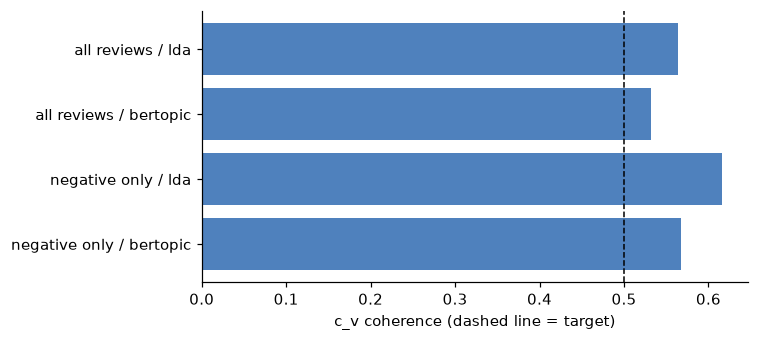

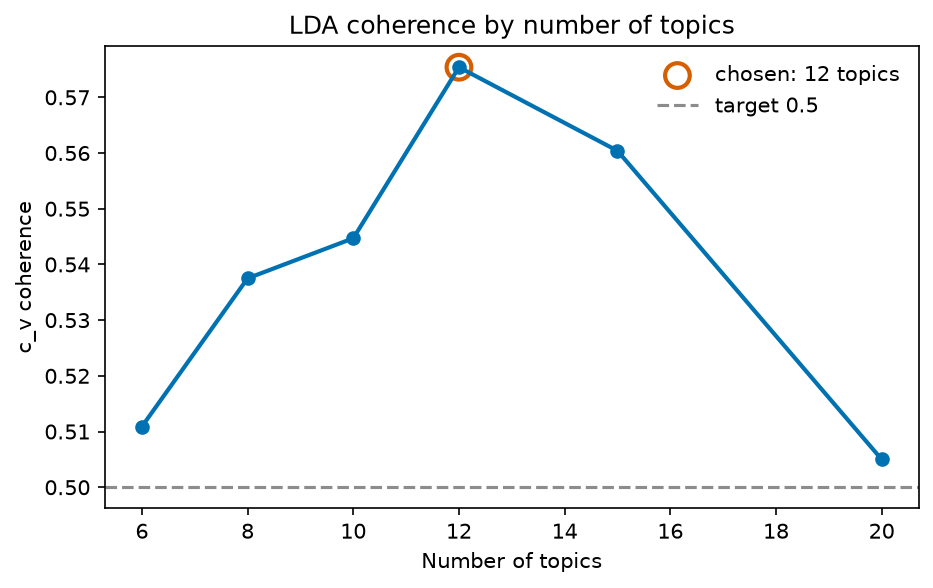

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
labels = coherence_table["scope"] + " / " + coherence_table["model"]
ax.barh(labels[::-1], coherence_table["c_v"][::-1], color=["#4f81bd" if ok else "#c0504d" for ok in coherence_table["meets 0.5"][::-1]])
ax.axvline(CFG.targets.topic_coherence, color="black", ls="--", lw=1)
ax.set_xlabel("c_v coherence (dashed line = target)"); plt.tight_layout(); plt.show()
show_figure("coherence_sweep.png")

### Topics ranked by how negative they are
`lift` above 1 means the topic is more likely to appear in a negative review than an average review is to be negative.

,topic,top_words,reviews,mean_score,negative_share,lift
0,56,china usa dog treat pet jerky chicken fda,304,2.73,0.5164,3.59
1,52,dent damage case shipment badly dented open arrive,331,3.17,0.3746,2.60
2,120,basket gift item send picture recipient box presentation,136,3.46,0.3309,2.30
3,84,sprout seed grow plant herb kit garden basil,200,3.54,0.3200,2.22
4,40,trap mole fly moth catch yard set critter,492,3.54,0.3089,2.15
5,137,bully stick dog chew smell rawhide odor puppy,119,3.57,0.2941,2.04
6,143,mango papaya dry fruit sulphur slice philippine mangosteen,104,3.79,0.2885,2.01
7,130,kona coffee blend hawaii roast tully bean island,128,3.68,0.2734,1.90
8,112,bacon spam ham sandwich salt smoke grease salad,156,3.69,0.2564,1.78
9,31,jerky beef jim slim jack link meat stick,536,3.82,0.2481,1.72


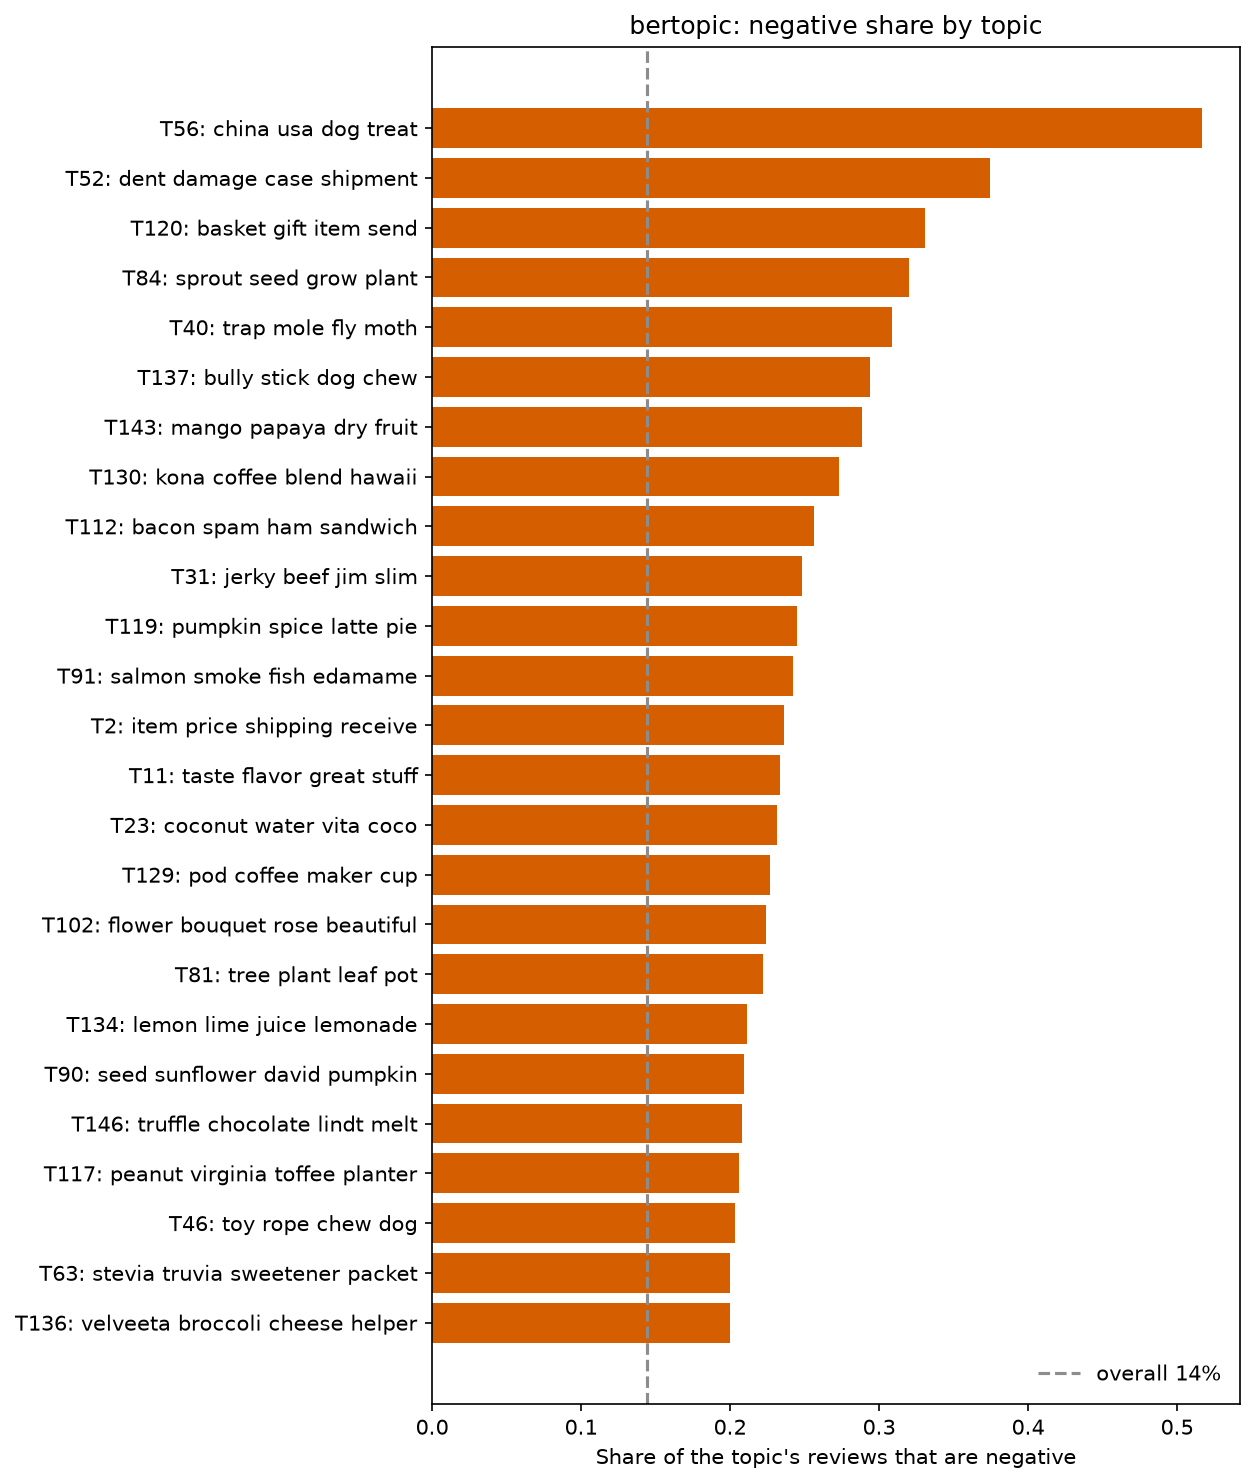

In [4]:
pd.set_option("display.max_colwidth", 80)
topics_all = pd.read_csv(REPORTS / "topics_bertopic.csv")
display(topics_all.head(10)[["topic", "top_words", "reviews", "mean_score", "negative_share", "lift"]])
show_figure("bertopic_topic_negativity.png")

### Topics inside negative reviews only
Modelling just the unhappy reviews shows *what* they complain about instead of what the whole catalogue talks about.

,topic,top_words,reviews,share,mean_score
0,0,coffee cup bean pod roast brew vanilla flavor,6713,0.1178,1.40
1,1,tea green chai leaf bag drink taste flavor,2996,0.0526,1.43
2,2,price oz pack pay store ounce amazon box,1905,0.0334,1.21
3,3,gluten cake bread flour free mix pancake bake,1693,0.0297,1.37
4,4,peanut butter nut almond cashew pb salt pistachio,1314,0.0231,1.35
5,5,cat food eat feed kitten kitty chicken pet,1233,0.0216,1.36
6,6,cooky cookie chip chocolate gooey fudge oreo chewy,1062,0.0186,1.49
7,7,taste stuff like bad flavor drink awful smell,922,0.0162,1.29
8,8,bar protein chocolate granola eat peanut snack calorie,855,0.0150,1.46
9,9,dog food feed ingredient meal vet corn meat,837,0.0147,1.36


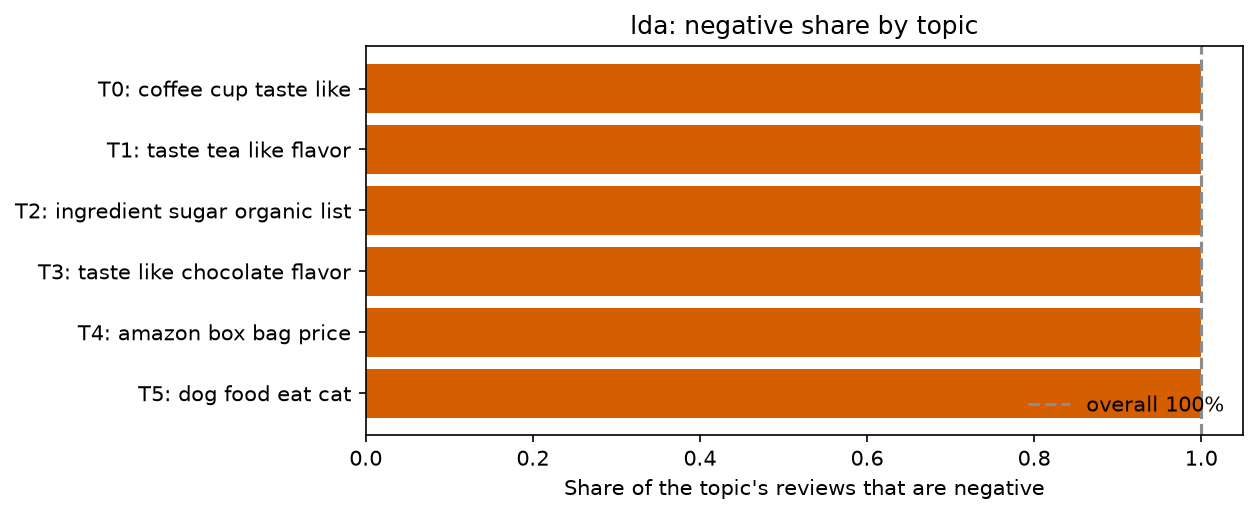

In [5]:
topics_neg = pd.read_csv(REPORTS / "topics_bertopic_negative.csv")
display(topics_neg.sort_values("reviews", ascending=False).head(10)[["topic", "top_words", "reviews", "share", "mean_score"]])
show_figure("lda_topic_negativity_negative.png")

## 2. Aspect-based sentiment (step 8)
A keyword lexicon (whole-word regex) tags sentences with one or more of ten aspects: taste, price, shipping,
packaging, freshness, quality, health, service, listing and safety. DistilBERT scores each tagged **sentence**:
at or below 0.25 negative, at or above 0.75 positive, in between mixed (left out of the shares).

* `neg_sentence_share`: of confident sentences about the aspect, the share that are negative.
* `pain_ratio`: how much more often negative reviews mention the aspect than positive ones do (1 = no difference).

In [6]:
if RUN_ASPECTS:
    from reviews import insights
    insights.run(CFG)
ins = read_json(REPORTS / f"{CFG.aspects.summary_name}.json")
print({k: ins[k] for k in ("reviews", "sentences", "aspect_sentences") if k in ins})
aspects = pd.read_csv(REPORTS / "aspect_summary.csv")
aspects

{'reviews': 392945, 'sentences': 2066356, 'aspect_sentences': 718148}


,aspect,reviews,mention_rate,neg_review_rate,pos_review_rate,pain_ratio,sentences,polar_sentences,neg_sentence_share,net_sentiment
0,taste,208271,0.5300,0.5058,0.5271,0.96,347437,328531,0.2103,0.5793
1,price,95044,0.2419,0.2151,0.2450,0.88,122574,108526,0.1554,0.6891
2,quality,71770,0.1826,0.1966,0.1768,1.11,98110,91443,0.2312,0.5376
3,health,77471,0.1972,0.1489,0.2063,0.72,117406,108682,0.1737,0.6526
4,listing,19263,0.0490,0.1127,0.0332,3.40,23230,19575,0.5485,-0.0970
5,shipping,42504,0.1082,0.1074,0.1091,0.98,50496,45796,0.1685,0.6630
6,service,19088,0.0486,0.1064,0.0380,2.80,22695,20702,0.3756,0.2489
7,packaging,23995,0.0611,0.0901,0.0524,1.72,29755,26592,0.3505,0.2990
8,freshness,27157,0.0691,0.0852,0.0663,1.28,32312,30800,0.2635,0.4730
9,safety,6334,0.0161,0.0394,0.0118,3.33,8015,7283,0.5996,-0.1992


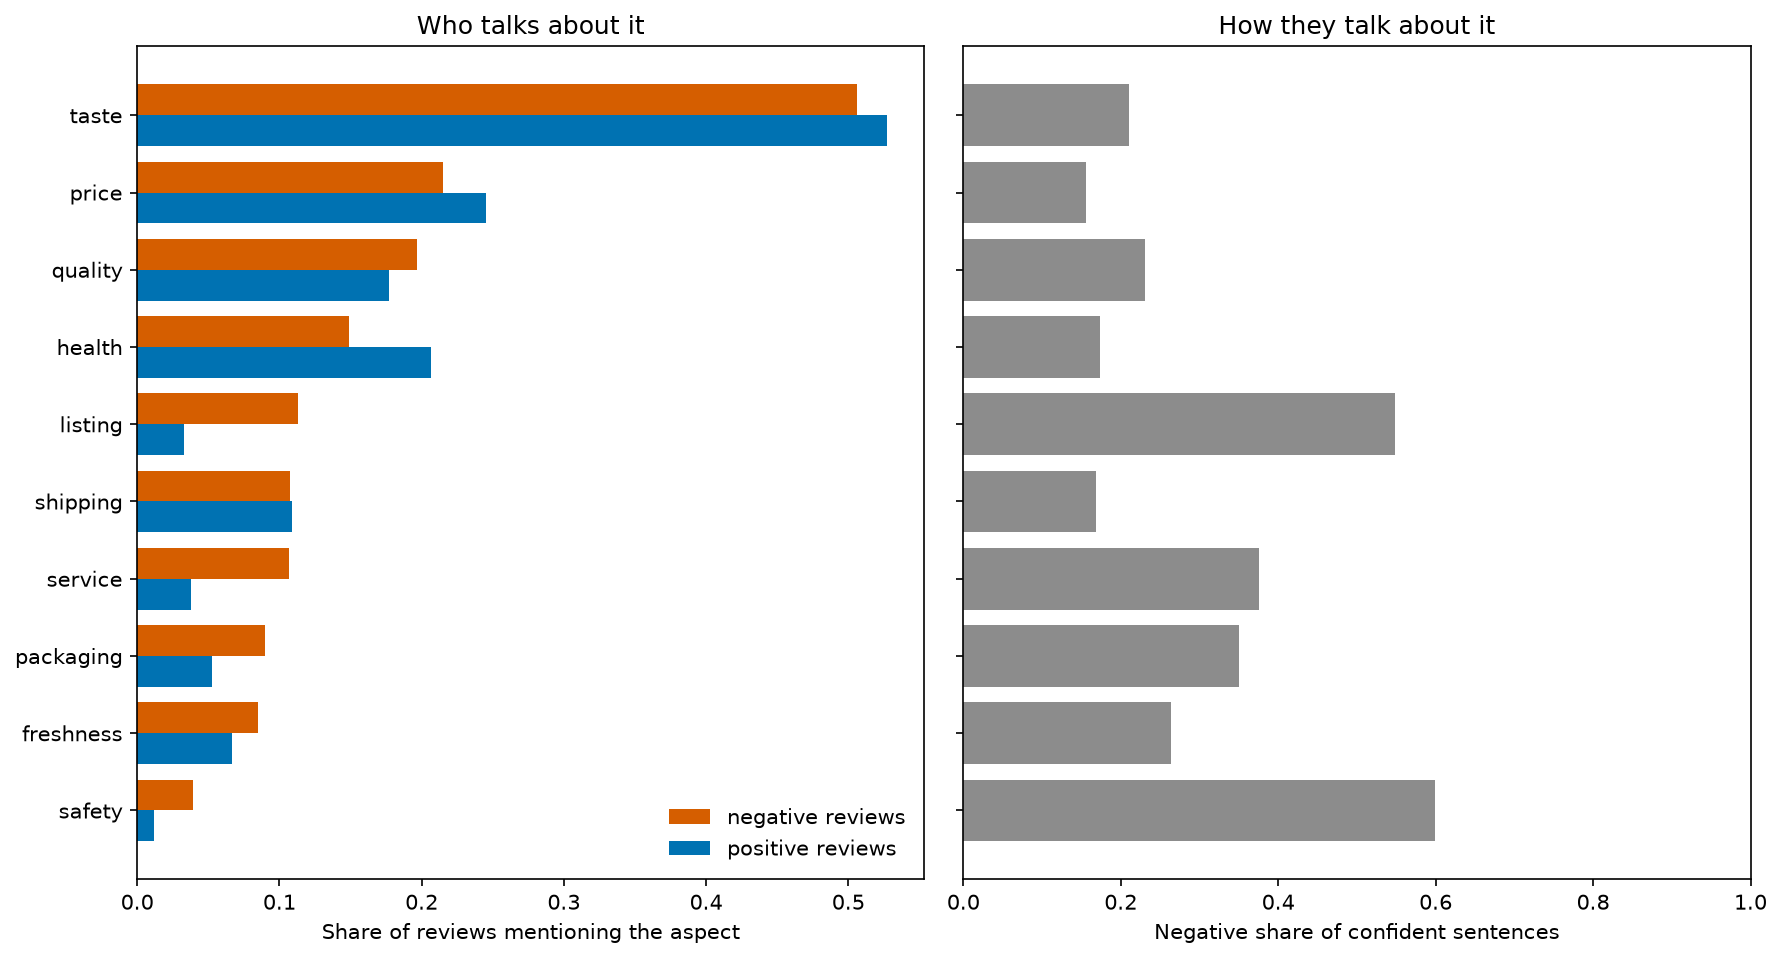

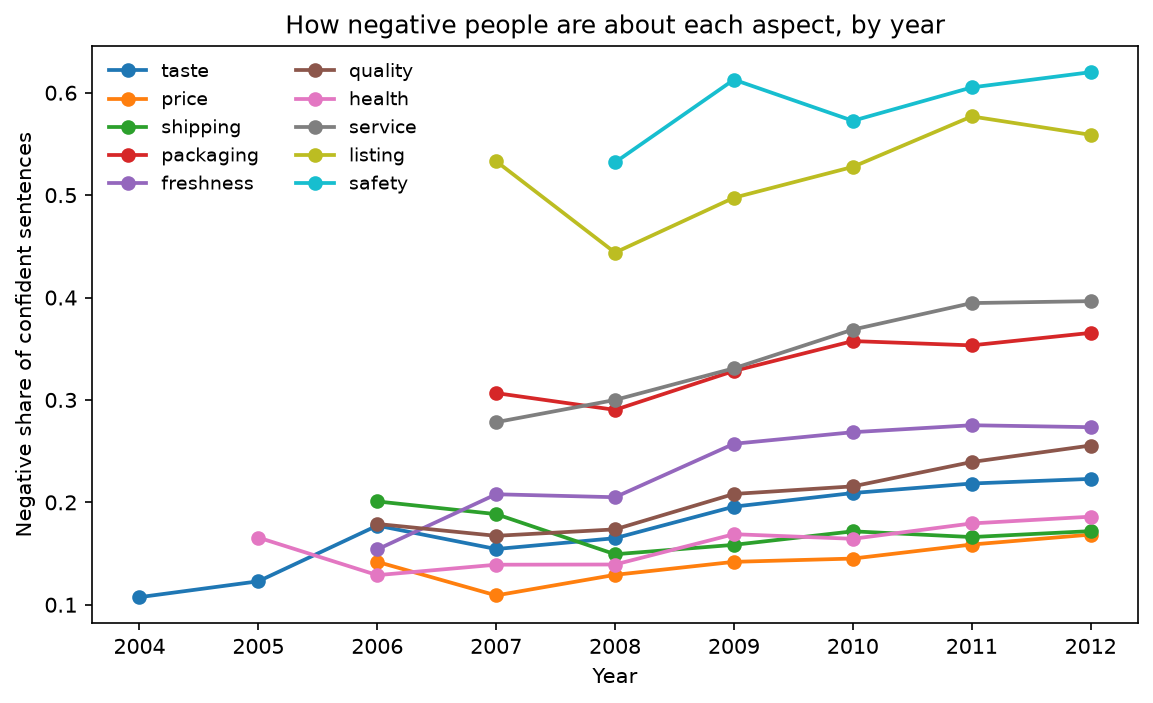

In [7]:
show_figure("aspect_pain_points.png")
show_figure("aspect_trend.png")

### Which aspects hurt most?
Ranked by the pain ratio, restricted to aspects with enough mentions to trust.

In [8]:
ranked = aspects[aspects["reviews"] >= 1000].sort_values("pain_ratio", ascending=False)
ranked[["aspect", "reviews", "mention_rate", "pain_ratio", "neg_sentence_share", "net_sentiment"]].reset_index(drop=True)

,aspect,reviews,mention_rate,pain_ratio,neg_sentence_share,net_sentiment
0,listing,19263,0.0490,3.40,0.5485,-0.0970
1,safety,6334,0.0161,3.33,0.5996,-0.1992
2,service,19088,0.0486,2.80,0.3756,0.2489
3,packaging,23995,0.0611,1.72,0.3505,0.2990
4,freshness,27157,0.0691,1.28,0.2635,0.4730
5,quality,71770,0.1826,1.11,0.2312,0.5376
6,shipping,42504,0.1082,0.98,0.1685,0.6630
7,taste,208271,0.5300,0.96,0.2103,0.5793
8,price,95044,0.2419,0.88,0.1554,0.6891
9,health,77471,0.1972,0.72,0.1737,0.6526


### Trend and drop flags
A month is flagged when its value is more than 2 standard deviations worse than the average of the previous 12 months (the baseline uses only earlier months).

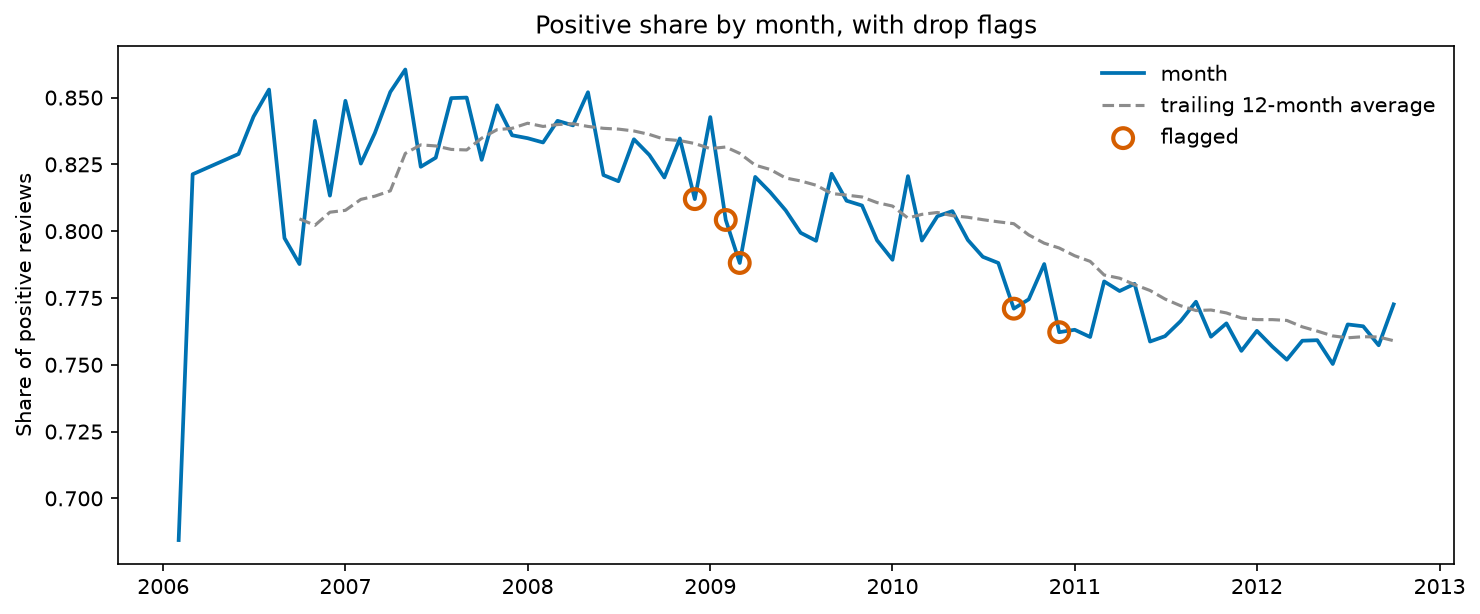

,value,baseline,z
month,,,
2008-12,0.8120,0.8328,-2.16
2009-02,0.8042,0.8315,-2.32
2009-03,0.7881,0.8291,-2.90
2010-09,0.7710,0.8028,-2.74
2010-12,0.7622,0.7937,-2.30


2009-08    shipping, packaging, freshness, service
2009-03                       taste, price, health
2010-09                 price, shipping, freshness
2008-06                             taste, quality
2009-02                              taste, health
2010-10                             taste, listing
2011-01                             price, listing
2009-05                        shipping, packaging
2012-09                          packaging, safety
2009-06                            quality, health
Name: aspects rising together, dtype: str

In [9]:
show_figure("monthly_drop_flags.png")
flags = ins["drop_flags"]
table = pd.DataFrame(flags["share_positive"]).T
table.index.name = "month"
display(table)
rises = flags.get("aspect_negativity_rises", {})
multi = {}
for aspect, months in rises.items():
    for month in months:
        multi.setdefault(month, []).append(aspect)
pd.Series({m: ", ".join(a) for m, a in sorted(multi.items(), key=lambda kv: -len(kv[1]))}, name="aspects rising together").head(10)

### What customers actually say
The most confidently negative sentences per aspect, as quotes for the report.

In [10]:
examples = pd.read_csv(REPORTS / "aspect_examples.csv")
pd.set_option("display.max_colwidth", 200)
examples.groupby("aspect").head(2).reset_index(drop=True)

,aspect,p_positive,sentence
0,taste,0.000488,"Since my husband and I are big coffee drinkers we look for bargains, when this was offered at a good price we made a purchase, this was the worst coffee either of us have had..horrible smell and e..."
1,taste,0.000496,This product is a pathetic blend of trashy ingredients which yield a paneer that is tasteless and without much structure after frying...
2,price,0.000480,"This is horrble horrible product and I am not even reffering to the nutritional value of it, I am leaving it to others."
3,price,0.000488,"Since my husband and I are big coffee drinkers we look for bargains, when this was offered at a good price we made a purchase, this was the worst coffee either of us have had..horrible smell and e..."
4,shipping,0.000511,this was a soory product.It was about the size of you thumb and my dog hated it and would not eat it.Waste of money and shipping.
5,shipping,0.000617,"It arrived in totally unacceptable form: moldy peppercorns, broken empty husks, withered ancient former peppercorns from a bygone era, gargantuan mutant peppercorns incompatible with any grinder I..."
6,packaging,0.000553,"Zero flavor, not even the fragrance of the right herbs or spices when loosely sealed containers were opened."
7,packaging,0.000553,"Zero flavor, not even the fragrance of the right herbs or spices when loosely sealed containers were opened."
8,freshness,0.000527,"Stale, flavorless garbage."
9,freshness,0.000527,This had to be the worst popcorn I ever eat.Stale and came all stuck toghter.Its had a bad aftertaste.I threw the rest away.What a waste.


## 3. Summaries (step 9)
For each aspect, the most representative negative reviews (closest to the group's average TF-IDF vector) are
summarised with `sshleifer/distilbart-cnn-12-6`. Long inputs are split into chunks, summarised, and the summaries
summarised again. The text is machine-written: check it against the example review Ids before quoting.

In [11]:
if RUN_SUMMARIES:
    from reviews import summarize
    summarize.run(CFG)
summary_path = REPORTS / f"{CFG.summary.report_name}.md"
from IPython.display import Markdown
display(Markdown(summary_path.read_text(encoding="utf-8"))) if summary_path.is_file() else print("missing:", summary_path)

# Pain-point summaries

Machine-written by `sshleifer/distilbart-cnn-12-6` from the most representative negative reviews of each aspect. Check against the example reviews before quoting.

## Overall (56,969 negative reviews)

Lipton's just needs to step it up and make it stronger so you can actually taste it, reviewer says . Amazon was kind enough to refund my purchase price .

Example review Ids: 258989, 566837, 62034, 28250, 472436

## Taste (28,910 negative reviews)

Lipton's just needs to step it up and make it stronger, reviewer says . Gluten free cookies were so dry and had no flavor at all . After each sip there is an after taste of some sort of chemical .

Example review Ids: 303532, 441772, 461899, 487560, 307393

## Price (12,302 negative reviews)

Lindt's marketing machine is doing itself a great disservice by continuing to perpetuate the lie that most people actually like the new recipe . The artificial chemicals used in coloring dog food are really just added to make the human consumer feel that the food is better balanced and has more variety .

Example review Ids: 566837, 441772, 474657, 133302, 62034

## Shipping (6,126 negative reviews)

The snap inside the individual packs were breaking up while packet is not even open and there was a white powder coming out and while eating you can feel it is not fresh at all . The coffee tasted like it'd been sitting in a warehouse the whole time . The taste really do not taste like real coconut . Amazon shipping is horrible . Amazon is great about replacing items but my last order was replaced multiple times .

Example review Ids: 160688, 81663, 112105, 184377, 102870

## Packaging (5,146 negative reviews)

This is a super food that should never be sold all-inclusive . Amazon shipping is horrible . Candy is not fresh-tasting and it looks almost oxidized or something -- a strange, muddled color of purple . The expiry date of the tea boxes is in 2011 .

Example review Ids: 81663, 231940, 25372, 296195, 449744

## Freshness (4,870 negative reviews)

Ground coffee becomes stale within less than 6 months . Amazon delivers coffee that was packed more than a YEAR before purchase date . The cookies tasted like a bunch of raw flours mixed together with a few chocolate chips scattered about .

Example review Ids: 99399, 81655, 415482, 247820, 258989

## Quality (11,226 negative reviews)

MiO Liquid is a "water enhancer" that makes water more flavorful without adding any calories . Walden Farm products don't taste great on their own, but are good mixed with the right foods . Lipton's just needs to step it up and make it stronger so you can actually taste it .

Example review Ids: 303532, 89619, 247629, 133454, 222370

## Health (8,503 negative reviews)

Gluten free cookies were so dry and had no flavor at all . They claim to have a nutty flavor but I did not detect that at all, they tasted like raw flours mixed together . MiO Liquid is a "water enhancer" that makes water more flavorful without adding any calories . The ingredients list is way too long for what it is .

Example review Ids: 258989, 303532, 18186, 89619, 152274

## Service (6,088 negative reviews)

Each bottle had about a half inch of foam on top and had a very strong plastic or soapy taste . Coffee purchased from AMAZON was received on July 14, 2010 but date on coffee bag indicates it was packed on June 30, 2009 (13 months old)

Example review Ids: 474657, 113514, 112105, 331332, 415482

## Listing (6,449 negative reviews)

Lindt's marketing machine is doing itself a great disservice by continuing to perpetuate the lie that most people actually like the new recipe . This product is falsely advertised as white tea . The price per ounce is higher than what I pay for a dog food with lots more real protein value .

Example review Ids: 28250, 125126, 16281, 389111, 305062

## Safety (2,256 negative reviews)

All Dogswell treats made in China are being investigated by the FDA because some dogs have died after consuming them . FDA is investigating whether the treats are actually made in the United States .

Example review Ids: 144543, 233999, 12280, 431675, 509888


## 4. Executive summary
The written executive summary of pain points (ranked pain points, flagged months, recommended actions and how far to
trust the numbers) is a separate document. The numbers behind it are the tables above.

The Streamlit app (`app/streamlit_app.py`) lets anyone paste a review or upload a CSV and get the same kind of
dashboard for their own data.